<a href="https://colab.research.google.com/github/CarlosFranciscoM-Urzua/EJERCICIOS_PLN_COLAB/blob/main/Practica_RNN_LSTM_GRU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Práctica: Modelos PNL basados en redes neuronales: RNN, LSTM y GRU**

**Montoya Urzúa Carlos Francisco**

PRÁCTICA GUIADA
Modelos de lenguaje basados en redes
neuronales
Asignatura: Procesamiento del Lenguaje Natural (PLN) · Unidad 5: Modelos de lenguaje y sus métricas · Tema: RNN, LSTM y GRU · Herramienta: Google Colab · Duración sugerida: 120 minutos.

#1.	Objetivo y situación de aprendizaje
Implementar y comparar redes neuronales recurrentes (RNN), Long Short-Term Memory (LSTM) y Gated Recurrent Units (GRU) para clasificar comentarios estudiantiles en positivos o negativos.

Se analizarán sus predicciones, exactitud y cantidad de parámetros.


Problema: una institución desea clasificar automáticamente opiniones sobre sus cursos.

Ejemplos: «La clase fue excelente» → positivo (1); «No entendí la explicación» → negativo (0).

El conjunto de 20 comentarios es exclusivamente didáctico; no sirve para obtener conclusiones generales sobre el rendimiento de los modelos.

#2.	Preparar el entorno en Google Colab
Crear un cuaderno llamado Practica_RNN_LSTM_GRU. Ejecutar cada celda en orden. En caso de que TensorFlow no esté disponible, instalarlo con !pip install tensorflow y reiniciar el entorno.


In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

print("TensorFlow: ", tf.__version__)

TensorFlow:  2.21.0


¿Para qué sirve cada biblioteca? NumPy gestiona arreglos; Pandas organiza los registros; TensorFlow/Keras construye y entrena modelos; Scikit-learn divide los datos y calcula métricas; Matplotlib genera gráficas.

# 3.	Crear el conjunto de datos

In [2]:
textos = [
    'La clase fue excelente',
    'Me gustó mucho la explicación',
    'Aprendí cosas interesantes',
    'El profesor explica muy bien',
    'La materia es interesante',
    'Estoy satisfecho con el curso',
    'La explicación fue clara',
    'El curso fue muy útil',
    'Disfruté mucho la clase',
    'El contenido fue excelente',

    'La clase fue aburrida',
    'No entendí la explicación',
    'El profesor explica mal',
    'La materia es complicada',
    'No me gustó el curso',
    'Estoy decepcionado con la clase',
    'La explicación fue confusa',
    'El curso fue muy malo',
    'No aprendí nada',
    'El contenido fue deficiente'
]

etiquetas = [1]*10 + [0]*10

df = pd.DataFrame({
    'Texto': textos,
    'Sentimiento': etiquetas
})
df

,Texto,Sentimiento
0,La clase fue excelente,1
1,Me gustó mucho la explicación,1
2,Aprendí cosas interesantes,1
3,El profesor explica muy bien,1
4,La materia es interesante,1
5,Estoy satisfecho con el curso,1
6,La explicación fue clara,1
7,El curso fue muy útil,1
8,Disfruté mucho la clase,1
9,El contenido fue excelente,1


Las primeras diez etiquetas corresponden a comentarios positivos (1) y las diez restantes a negativos (0).
Comprobar que el DataFrame tenga 20 filas.

# 4.	Tokenizar y rellenar secuencias

In [3]:
tokenizer = Tokenizer(
    num_words=1000,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(textos)
secuencias = tokenizer.texts_to_sequences(textos)

X = pad_sequences(secuencias, maxlen=10, padding='post')
y = np.array(etiquetas)

print("Vocabulario: ")
display(tokenizer.word_index)
print('Primera secuencia: ', X[0])

Vocabulario: 


{'<OOV>': 1,
 'la': 2,
 'fue': 3,
 'el': 4,
 'clase': 5,
 'explicación': 6,
 'curso': 7,
 'muy': 8,
 'no': 9,
 'excelente': 10,
 'me': 11,
 'gustó': 12,
 'mucho': 13,
 'aprendí': 14,
 'profesor': 15,
 'explica': 16,
 'materia': 17,
 'es': 18,
 'estoy': 19,
 'con': 20,
 'contenido': 21,
 'cosas': 22,
 'interesantes': 23,
 'bien': 24,
 'interesante': 25,
 'satisfecho': 26,
 'clara': 27,
 'útil': 28,
 'disfruté': 29,
 'aburrida': 30,
 'entendí': 31,
 'mal': 32,
 'complicada': 33,
 'decepcionado': 34,
 'confusa': 35,
 'malo': 36,
 'nada': 37,
 'deficiente': 38}

Primera secuencia:  [ 2  5  3 10  0  0  0  0  0  0]


La tokenización asigna identificadores numéricos a las palabras. El relleno (padding) agrega ceros para que todas las entradas tengan diez posiciones. El token <OOV> representa palabras no conocidas por el vocabulario.

#5.	Separar entrenamiento y prueba

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print('Entrenamiento: ', len(X_train))
print("Prueba: ", len(X_test))

Entrenamiento:  14
Prueba:  6


Se reservan 14 comentarios para entrenamiento y 6 para prueba. La estratificación mantiene la proporción de clases. La muestra es tan pequeña que una sola predicción cambia considerablemente la exactitud.

#6.	Construir y entrenar una RNN

In [5]:
tf.keras.utils.set_random_seed(42)

modelo_rnn = Sequential([
    tf.keras.Input(shape=(10,)),
    Embedding(input_dim=1000, output_dim=16, mask_zero=True),
    SimpleRNN(16),
    Dense(1, activation='sigmoid')
])

modelo_rnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])

modelo_rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,545 (64.63 KB)

 Trainable params: 16,545 (64.63 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
historial_rnn = modelo_rnn.fit(
    X_train, y_train, epochs=20, batch_size=4,
    validation_split=0.2, verbose=1
)

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - accuracy: 0.4545 - loss: 0.7016 - val_accuracy: 0.3333 - val_loss: 0.7084
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5455 - loss: 0.6778 - val_accuracy: 0.3333 - val_loss: 0.7256
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.7273 - loss: 0.6583 - val_accuracy: 0.3333 - val_loss: 0.7428
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8182 - loss: 0.6393 - val_accuracy: 0.0000e+00 - val_loss: 0.7606
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9091 - loss: 0.6202 - val_accuracy: 0.0000e+00 - val_loss: 0.7797
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9091 - loss: 0.6006 - val_accuracy: 0.0000e+00 - val_loss: 0.8004
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 0.5801 - val_accuracy: 0.0000e+00 - val_loss: 0.8232
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 0.5586 - val_accuracy: 0.0000e+0

Interpretación: Embedding aprende vectores para los tokens; SimpleRNN procesa la secuencia y mantiene un estado oculto; Dense con sigmoid entrega una puntuación entre 0 y 1. La pérdida binary_crossentropy se utiliza para clasificación binaria. Observar cómo cambian loss y accuracy por época.

#7.	Construir y entrenar una LSTM

In [ ]:
tf.keras.utils.set_random_seed(42)

modelo_lstm = Sequential([
    tf.keras.Input(shape=(10,)),
    Embedding(input_dim=1000, output_dim=16, mask_zero=True),
    LSTM(16),
    Dense(1, activation='sigmoid')
])

modelo_lstm.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

historial_lstm = modelo_lstm.fit(
    X_train, y_train, epochs=20,
    batch_size=4, validation_split=0.2, verbose=1
)

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step - accuracy: 0.6364 - loss: 0.6914 - val_accuracy: 0.3333 - val_loss: 0.6946
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6364 - loss: 0.6885 - val_accuracy: 0.3333 - val_loss: 0.6965
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7273 - loss: 0.6863 - val_accuracy: 0.3333 - val_loss: 0.6984
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7273 - loss: 0.6839 - val_accuracy: 0.3333 - val_loss: 0.7002
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7273 - loss: 0.6815 - val_accuracy: 0.3333 - val_loss: 0.7021
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7273 - loss: 0.6789 - val_accuracy: 0.3333 - val_loss: 0.7041
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8182 - loss: 0.6761 - val_accuracy: 0.3333 - val_loss: 0.7063
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8182 - loss: 0.6729 - val_accuracy: 0.3333 - val_loss: 0.7086

La LSTM incorpora un estado de memoria y compuertas de olvido, entrada y salida. Estos mecanismos permiten gestionar información relevante de pasos anteriores y pueden facilitar el aprendizaje de dependencias largas.

#8.	Construir y entrenar una GRU


In [ ]:
tf.keras.utils.set_random_seed(42)

modelo_gru = Sequential([
    tf.keras.Input(shape=(10,)),
    Embedding(
        input_dim=1000,
        output_dim=16,
        mask_zero=True
    ),
    GRU(16),
    Dense(1, activation='sigmoid')
])

modelo_gru.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

historial_gru = modelo_gru.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 223ms/step - accuracy: 0.4545 - loss: 0.6947 - val_accuracy: 0.6667 - val_loss: 0.6875
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6364 - loss: 0.6902 - val_accuracy: 0.3333 - val_loss: 0.6906
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6364 - loss: 0.6867 - val_accuracy: 0.3333 - val_loss: 0.6933
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6364 - loss: 0.6834 - val_accuracy: 0.3333 - val_loss: 0.6959
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.6364 - loss: 0.6800 - val_accuracy: 0.3333 - val_loss: 0.6985
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8182 - loss: 0.6765 - val_accuracy: 0.3333 - val_loss: 0.7012
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8182 - loss: 0.6728 - val_accuracy: 0.3333 - val_loss: 0.7040
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8182 - loss: 0.6688 - val_accuracy: 0.3333 - val_loss: 0.7070

La GRU utiliza compuertas de actualización y reinicio. Suele requerir menos parámetros que una LSTM comparable, pero su exactitud depende de los datos y de la configuración.

#9.	Evaluar y comparar los tres modelos


In [ ]:
modelos = {
    'RNN': modelo_rnn,
    'LSTM': modelo_lstm,
    'GRU': modelo_gru
}

resultados = []

for nombre, modelo in modelos.items():
    probabilidades = modelo.predict(X_test, verbose=0)
    clases = (probabilidades >= 0.5).astype(int).flatten()
    exactitud = accuracy_score(y_test, clases)

    resultados.append({
        'Modelo': nombre,
        'Exactitud': exactitud,
        'Parametros': modelo.count_params()
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados)

,Modelo,Exactitud,Parametros
0,RNN,0.333333,16545
1,LSTM,0.333333,18129
2,GRU,0.333333,17649


La exactitud es el número de predicciones correctas dividido entre el total de casos de prueba. El número de parámetros ayuda a comparar la complejidad de las arquitecturas. No interpretar diferencias pequeñas como evidencia de superioridad: solo hay seis observaciones de prueba.

#10.	Visualizar la comparación


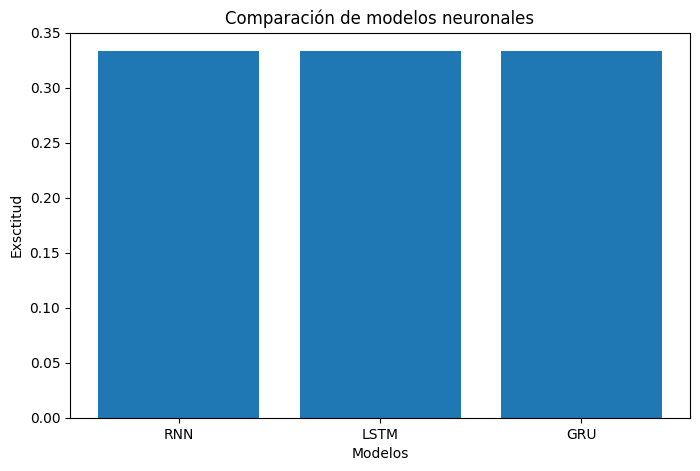

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(tabla_resultados['Modelo'], tabla_resultados['Exactitud'])
plt.title('Comparación de modelos neuronales')
plt.xlabel('Modelos')
plt.ylabel('Exsctitud')
plt.show()

Analizar:
* **¿Qué modelo obtuvo la mayor exactitud?**

Los tres modelos obtuvieron la misma exactitud.

* **¿Cuál empleó menos parámetros?**

RNN empleó menos parámetros.

* **¿Coinciden ambos criterios?**

Sí.



# 11.	Clasificar un comentario nuevo

In [ ]:
nuevo_texto = ['El curso fue excelente']
nueva_secuencia = tokenizer.texts_to_sequences(nuevo_texto)
nueva_entrada = pad_sequences(
    nueva_secuencia,
    maxlen=10,
    padding='post'
)

prediccion = modelo_lstm.predict(
    nueva_entrada,
    verbose=0
)[0][0]
print('Puntuación positiva: ', float(prediccion))
print("Positivo" if prediccion >= 0.5 else "Negativo")

Puntuación positiva:  0.5555154085159302
Positivo


Un resultado ilustrativo de 0.82 se clasifica como positivo al utilizar el umbral de 0.5. No es un resultado garantizado: el valor real depende del entrenamiento y de los datos. Una puntuación alta tampoco implica que el modelo esté bien calibrado.

In [ ]:
nuevo_texto = ['El curso fue excelente']
nueva_secuencia = tokenizer.texts_to_sequences(nuevo_texto)
nueva_entrada = pad_sequences(
    nueva_secuencia,
    maxlen=10,
    padding='post'
)

prediccion = modelo_rnn.predict(
    nueva_entrada,
    verbose=0
)[0][0]
print('Puntuación positiva: ', float(prediccion))
print("Positivo" if prediccion >= 0.5 else "Negativo")

Puntuación positiva:  0.2429669052362442
Negativo


In [ ]:
nuevo_texto = ['El curso fue excelente']
nueva_secuencia = tokenizer.texts_to_sequences(nuevo_texto)
nueva_entrada = pad_sequences(
    nueva_secuencia,
    maxlen=10,
    padding='post'
)

prediccion = modelo_gru.predict(
    nueva_entrada,
    verbose=0
)[0][0]
print('Puntuación positiva: ', float(prediccion))
print("Positivo" if prediccion >= 0.5 else "Negativo")

Puntuación positiva:  0.5458213686943054
Positivo


# 12.	Ejercicios adicionales
##Ejercicio 1:
Agregar diez comentarios positivos y diez negativos; volver a crear el vocabulario, las secuencias y la división de datos antes de entrenar nuevamente.

In [7]:
textos = [
    'La clase fue excelente',
    'Me gustó mucho la explicación',
    'Aprendí cosas interesantes',
    'El profesor explica muy bien',
    'La materia es interesante',
    'Estoy satisfecho con el curso',
    'La explicación fue clara',
    'El curso fue muy útil',
    'Disfruté mucho la clase',
    'El contenido fue excelente',
    # 10 comentarios positivos adicionales
    'Las clases son muy dinámicas y participativas',
    'Me encantó la paciencia del profesor',
    'El material complementario ayuda muchísimo',
    'Resolví todas mis dudas con los ejercicios',
    'La plataforma del curso es excelente y fluida',
    'Cada tema se explica de forma muy práctica',
    'Es el mejor curso que he tomado este año',
    'Me motiva bastante seguir aprendiendo sobre esto',
    'La metodología aplicada es sumamente efectiva',
    'La atención a los estudiantes es excepcional',

    'La clase fue aburrida',
    'No entendí la explicación',
    'El profesor explica mal',
    'La materia es complicada',
    'No me gustó el curso',
    'Estoy decepcionado con la clase',
    'La explicación fue confusa',
    'El curso fue muy malo',
    'No aprendí nada',
    'El contenido fue deficiente',
    # 10 comentarios negativos adicionales
    'La clase se hace demasiado larga y pesada',
    'Las diapositivas tienen demasiada teoría y aburren',
    'El audio del profesor es pésimo y no se entiende',
    'Los ejercicios prácticos no se relacionan con el tema',
    'Falta de apoyo y nula comunicación por el docente',
    'No hay retroalimentación sobre las tareas entregadas',
    'El temario está completamente desactualizado',
    'Perdí el interés desde la primera sesión',
    'Los ejemplos mostrados son muy confusos e inútiles',
    'No recomendaría este curso a nadie por su mala calidad'
]

etiquetas = [1]*20 + [0]*20

df = pd.DataFrame({
    'Texto': textos,
    'Sentimiento': etiquetas
})
df

,Texto,Sentimiento
0,La clase fue excelente,1
1,Me gustó mucho la explicación,1
2,Aprendí cosas interesantes,1
3,El profesor explica muy bien,1
4,La materia es interesante,1
5,Estoy satisfecho con el curso,1
6,La explicación fue clara,1
7,El curso fue muy útil,1
8,Disfruté mucho la clase,1
9,El contenido fue excelente,1


In [8]:
tokenizer = Tokenizer(
    num_words=1000,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(textos)
secuencias = tokenizer.texts_to_sequences(textos)

X = pad_sequences(secuencias, maxlen=10, padding='post')
y = np.array(etiquetas)

print("Vocabulario: ")
display(tokenizer.word_index)
print('Primera secuencia: ', X[0])

Vocabulario: 


{'<OOV>': 1,
 'la': 2,
 'el': 3,
 'fue': 4,
 'es': 5,
 'curso': 6,
 'no': 7,
 'muy': 8,
 'y': 9,
 'clase': 10,
 'me': 11,
 'explicación': 12,
 'profesor': 13,
 'con': 14,
 'los': 15,
 'se': 16,
 'excelente': 17,
 'explica': 18,
 'las': 19,
 'del': 20,
 'gustó': 21,
 'mucho': 22,
 'aprendí': 23,
 'materia': 24,
 'estoy': 25,
 'contenido': 26,
 'son': 27,
 'ejercicios': 28,
 'tema': 29,
 'de': 30,
 'este': 31,
 'sobre': 32,
 'a': 33,
 'por': 34,
 'cosas': 35,
 'interesantes': 36,
 'bien': 37,
 'interesante': 38,
 'satisfecho': 39,
 'clara': 40,
 'útil': 41,
 'disfruté': 42,
 'clases': 43,
 'dinámicas': 44,
 'participativas': 45,
 'encantó': 46,
 'paciencia': 47,
 'material': 48,
 'complementario': 49,
 'ayuda': 50,
 'muchísimo': 51,
 'resolví': 52,
 'todas': 53,
 'mis': 54,
 'dudas': 55,
 'plataforma': 56,
 'fluida': 57,
 'cada': 58,
 'forma': 59,
 'práctica': 60,
 'mejor': 61,
 'que': 62,
 'he': 63,
 'tomado': 64,
 'año': 65,
 'motiva': 66,
 'bastante': 67,
 'seguir': 68,
 'aprendiendo'

Primera secuencia:  [ 2 10  4 17  0  0  0  0  0  0]


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print('Entrenamiento: ', len(X_train))
print("Prueba: ", len(X_test))

Entrenamiento:  28
Prueba:  12


In [10]:
tf.keras.utils.set_random_seed(42)

def build_model_rnn ():
    modelo_rnn = Sequential([
        tf.keras.Input(shape=(10,)),
        Embedding(input_dim=1000, output_dim=16, mask_zero=True),
        SimpleRNN(16),
        Dense(1, activation='sigmoid')
    ])

    modelo_rnn.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy'])

    modelo_rnn.summary()

    return modelo_rnn

modelo_rnn = build_model_rnn()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,545 (64.63 KB)

 Trainable params: 16,545 (64.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
historial_rnn = modelo_rnn.fit(
    X_train, y_train, epochs=20, batch_size=4,
    validation_split=0.2, verbose=1
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step - accuracy: 0.5909 - loss: 0.6891 - val_accuracy: 0.3333 - val_loss: 0.7350
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7273 - loss: 0.6511 - val_accuracy: 0.1667 - val_loss: 0.7505
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8636 - loss: 0.6190 - val_accuracy: 0.1667 - val_loss: 0.7695
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9091 - loss: 0.5856 - val_accuracy: 0.1667 - val_loss: 0.7932
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9091 - loss: 0.5492 - val_accuracy: 0.1667 - val_loss: 0.8233
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9091 - loss: 0.5089 - val_accuracy: 0.1667 - val_loss: 0.8624
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9091 - loss: 0.4647 - val_accuracy: 0.1667 - val_loss: 0.9137
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9091 - loss: 0.4176 - val_accuracy: 0.1667 - val_loss: 0.9811

In [12]:
tf.keras.utils.set_random_seed(42)

def build_model_lstm():
    modelo_lstm = Sequential([
        tf.keras.Input(shape=(10,)),
        Embedding(input_dim=1000, output_dim=16, mask_zero=True),
        LSTM(16),
        Dense(1, activation='sigmoid')
    ])

    modelo_lstm.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return modelo_lstm

modelo_lstm = build_model_lstm()

historial_lstm = modelo_lstm.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.3182 - loss: 0.6952 - val_accuracy: 0.6667 - val_loss: 0.6928
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6818 - loss: 0.6903 - val_accuracy: 0.5000 - val_loss: 0.6946
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6864 - val_accuracy: 0.1667 - val_loss: 0.6970
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6819 - val_accuracy: 0.1667 - val_loss: 0.6999
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6764 - val_accuracy: 0.1667 - val_loss: 0.7037
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8636 - loss: 0.6693 - val_accuracy: 0.3333 - val_loss: 0.7087
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8636 - loss: 0.6600 - val_accuracy: 0.3333 - val_loss: 0.7156
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6476 - val_accuracy: 0.3333 - val_loss: 0.7252


In [13]:
tf.keras.utils.set_random_seed(42)

def build_model_gru():
    modelo_gru = Sequential([
        tf.keras.Input(shape=(10,)),
        Embedding(
            input_dim=1000,
            output_dim=16,
            mask_zero=True
        ),
        GRU(16),
        Dense(1, activation='sigmoid')
    ])

    modelo_gru.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return modelo_gru

modelo_gru = build_model_gru()

historial_gru = modelo_gru.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - accuracy: 0.3182 - loss: 0.6966 - val_accuracy: 0.5000 - val_loss: 0.6913
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6364 - loss: 0.6890 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9545 - loss: 0.6832 - val_accuracy: 0.5000 - val_loss: 0.6960
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9091 - loss: 0.6770 - val_accuracy: 0.3333 - val_loss: 0.6991
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9091 - loss: 0.6697 - val_accuracy: 0.3333 - val_loss: 0.7028
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6608 - val_accuracy: 0.3333 - val_loss: 0.7071
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6497 - val_accuracy: 0.3333 - val_loss: 0.7123
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6358 - val_accuracy: 0.3333 - val_loss: 0.7188

In [14]:
modelos = {
    'RNN': modelo_rnn,
    'LSTM': modelo_lstm,
    'GRU': modelo_gru
}

resultados = []

for nombre, modelo in modelos.items():
    probabilidades = modelo.predict(X_test, verbose=0)
    clases = (probabilidades >= 0.5).astype(int).flatten()
    exactitud = accuracy_score(y_test, clases)

    resultados.append({
        'Modelo': nombre,
        'Exactitud': exactitud,
        'Parametros': modelo.count_params()
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados)

,Modelo,Exactitud,Parametros
0,RNN,0.333333,16545
1,LSTM,0.500000,18129
2,GRU,0.333333,17649


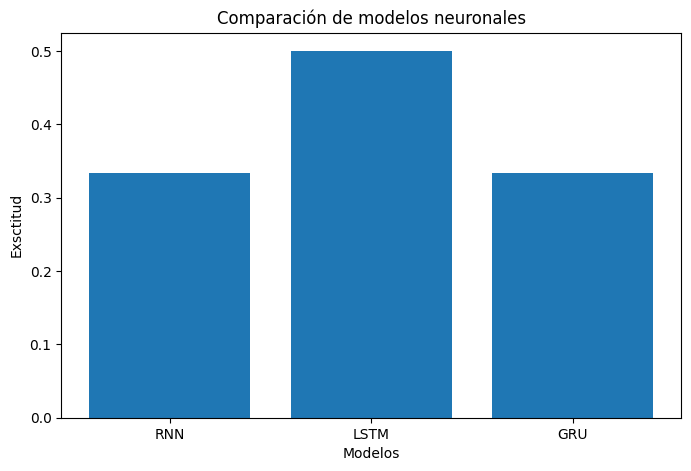

In [15]:
plt.figure(figsize=(8,5))
plt.bar(tabla_resultados['Modelo'], tabla_resultados['Exactitud'])
plt.title('Comparación de modelos neuronales')
plt.xlabel('Modelos')
plt.ylabel('Exsctitud')
plt.show()

Aquí se ve que el modelo LSTM consiguió una mejor exactitud, mientras que el RNN y GRU obtuvieron la misma exactitud. Posiblemente necesitan más epocas.

##Ejercicio 2:
Comparar 10, 30 y 50 épocas; registrar accuracy de entrenamiento y prueba y explicar el posible sobreajuste.

In [17]:
modelo_rnn_10 = build_model_rnn()

historial_rnn_10 = modelo_rnn_10.fit(
    X_train, y_train, epochs=10, batch_size=4,
    validation_split=0.2, verbose=1
)

modelo_rnn_30 = build_model_rnn()

historial_rnn_30 = modelo_rnn_30.fit(
    X_train, y_train, epochs=30, batch_size=4,
    validation_split=0.2, verbose=1
)

modelo_rnn_50 = build_model_rnn()

historial_rnn_50 = modelo_rnn_50.fit(
    X_train, y_train, epochs=50, batch_size=4,
    validation_split=0.2, verbose=1
)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,545 (64.63 KB)

 Trainable params: 16,545 (64.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.4091 - loss: 0.6978 - val_accuracy: 0.5000 - val_loss: 0.7134
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8636 - loss: 0.6585 - val_accuracy: 0.5000 - val_loss: 0.7253
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8636 - loss: 0.6236 - val_accuracy: 0.3333 - val_loss: 0.7402
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8636 - loss: 0.5863 - val_accuracy: 0.1667 - val_loss: 0.7593
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9091 - loss: 0.5451 - val_accuracy: 0.1667 - val_loss: 0.7839
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9545 - loss: 0.4998 - val_accuracy: 0.1667 - val_loss: 0.8158
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9545 - loss: 0.4512 - val_accuracy: 0.0000e+00 - val_loss: 0.8570
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9545 - loss: 0.4017 - val_accuracy: 0.0000e+00 - val_loss:

... (8 outputs left out)

 Total params: 16,545 (64.63 KB)

 Trainable params: 16,545 (64.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.2727 - loss: 0.7189 - val_accuracy: 0.5000 - val_loss: 0.6825
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6364 - loss: 0.6831 - val_accuracy: 0.3333 - val_loss: 0.6909
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9545 - loss: 0.6558 - val_accuracy: 0.3333 - val_loss: 0.7002
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9545 - loss: 0.6289 - val_accuracy: 0.3333 - val_loss: 0.7113
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.5998 - val_accuracy: 0.0000e+00 - val_loss: 0.7258
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.5670 - val_accuracy: 0.0000e+00 - val_loss: 0.7448
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 0.5299 - val_accuracy: 0.0000e+00 - val_loss: 0.7696
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.4883 - val_accuracy: 0.0000e+00 - v

In [18]:
modelo_lstm_10 = build_model_lstm()
historial_lstm_10 = modelo_lstm.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

modelo_lstm_30 = build_model_lstm()
historial_lstm_30 = modelo_lstm.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

modelo_lstm_50 = build_model_lstm()
historial_lstm_50 = modelo_lstm.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9091 - loss: 0.2303 - val_accuracy: 0.1667 - val_loss: 1.9815
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9545 - loss: 0.2125 - val_accuracy: 0.1667 - val_loss: 2.0123
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 0.1964 - val_accuracy: 0.1667 - val_loss: 2.0195
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 1.0000 - loss: 0.1818 - val_accuracy: 0.1667 - val_loss: 2.0037
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.1683 - val_accuracy: 0.1667 - val_loss: 1.9656
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 0.1560 - val_accuracy: 0.1667 - val_loss: 1.9090
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 0.1446 - val_accuracy: 0.1667 - val_loss: 1.8446
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 0.1342 - val_accuracy: 0.1667 - val_loss: 1.7906


In [19]:
modelo_gru_10 = build_model_gru()
historial_gru_10 = modelo_gru_10.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

modelo_gru_30 = build_model_gru()
historial_gru_30 = modelo_gru.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

modelo_gru_50 = build_model_gru()
historial_gru_50 = modelo_gru.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step - accuracy: 0.2727 - loss: 0.6973 - val_accuracy: 0.6667 - val_loss: 0.6887
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5455 - loss: 0.6900 - val_accuracy: 0.5000 - val_loss: 0.6911
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9091 - loss: 0.6844 - val_accuracy: 0.5000 - val_loss: 0.6942
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9091 - loss: 0.6781 - val_accuracy: 0.3333 - val_loss: 0.6977
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8636 - loss: 0.6706 - val_accuracy: 0.3333 - val_loss: 0.7017
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8636 - loss: 0.6613 - val_accuracy: 0.3333 - val_loss: 0.7065
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8636 - loss: 0.6496 - val_accuracy: 0.3333 - val_loss: 0.7122
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9091 - loss: 0.6349 - val_accuracy: 0.3333 - val_loss: 0.7193

,Modelo,Exactitud,Parametros
0,RNN,0.166667,16545
1,LSTM,0.500000,18129
2,GRU,0.416667,17649


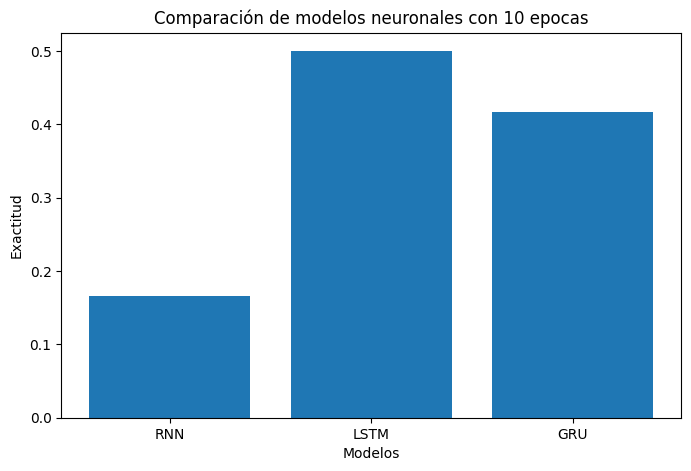

In [21]:
modelos_10 = {
    'RNN': modelo_rnn_10,
    'LSTM': modelo_lstm_10,
    'GRU': modelo_gru_10
}

modelos_30 = {
    'RNN': modelo_rnn_30,
    'LSTM': modelo_lstm_30,
    'GRU': modelo_gru_30
}

modelos_50 = {
    'RNN': modelo_rnn_50,
    'LSTM': modelo_lstm_50,
    'GRU': modelo_gru_50
}

def comparar_modelos(modelos, n_epocas):
    resultados = []

    for nombre, modelo in modelos.items():
        probabilidades = modelo.predict(X_test, verbose=0)
        clases = (probabilidades >= 0.5).astype(int).flatten()
        exactitud = accuracy_score(y_test, clases)

        resultados.append({
            'Modelo': nombre,
            'Exactitud': exactitud,
            'Parametros': modelo.count_params()
        })

    tabla_resultados = pd.DataFrame(resultados)
    display(tabla_resultados)

    plt.figure(figsize=(8,5))
    plt.bar(tabla_resultados['Modelo'], tabla_resultados['Exactitud'])
    plt.title('Comparación de modelos neuronales con ' + str(n_epocas) + ' epocas')
    plt.xlabel('Modelos')
    plt.ylabel('Exactitud')
    plt.show()


comparar_modelos(modelos=modelos_10, n_epocas=10)

,Modelo,Exactitud,Parametros
0,RNN,0.416667,16545
1,LSTM,0.750000,18129
2,GRU,0.333333,17649


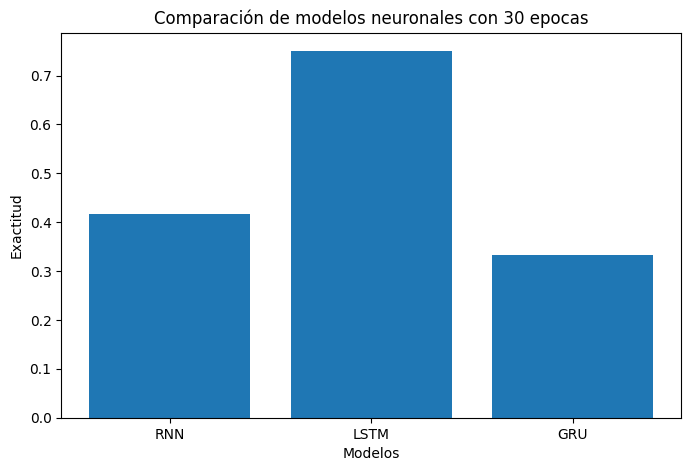

In [22]:
comparar_modelos(modelos=modelos_30, n_epocas=30)

,Modelo,Exactitud,Parametros
0,RNN,0.416667,16545
1,LSTM,0.416667,18129
2,GRU,0.666667,17649


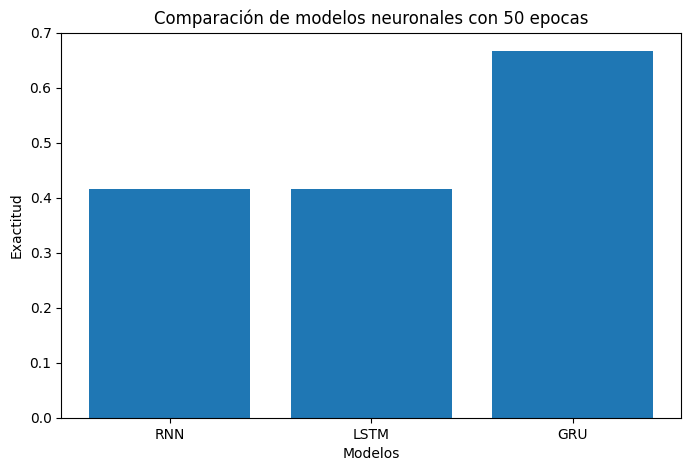

In [23]:
comparar_modelos(modelos=modelos_50, n_epocas=50)

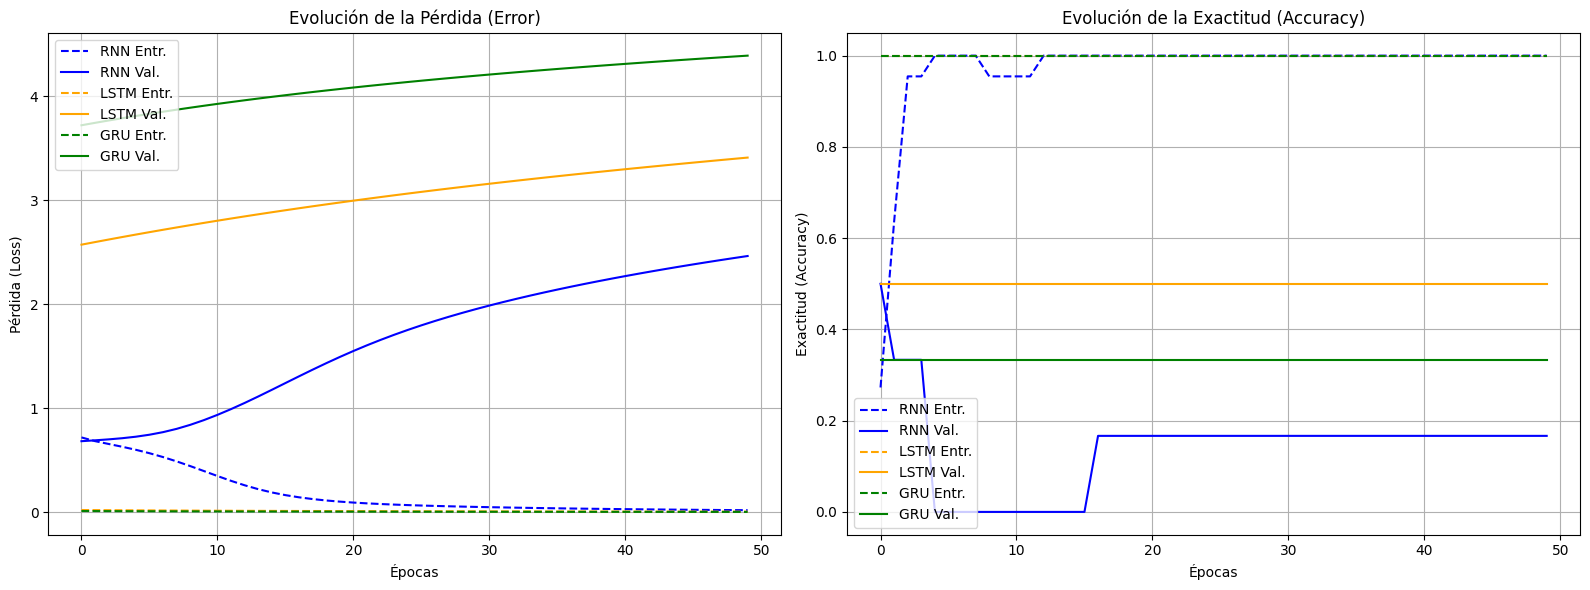

In [24]:
def graficar_historiales(historial_rnn, historial_lstm, historial_gru):
    """
    Genera dos gráficos comparativos:
    1. Evolución de la pérdida (loss/error) de entrenamiento y validación para los 3 modelos.
    2. Evolución de la exactitud (accuracy) de entrenamiento y validación para los 3 modelos.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Gráfico de Pérdida (Loss / Error)
    ax1.plot(historial_rnn.history['loss'], label='RNN Entr.', linestyle='--', color='blue')
    ax1.plot(historial_rnn.history['val_loss'], label='RNN Val.', linestyle='-', color='blue')

    ax1.plot(historial_lstm.history['loss'], label='LSTM Entr.', linestyle='--', color='orange')
    ax1.plot(historial_lstm.history['val_loss'], label='LSTM Val.', linestyle='-', color='orange')

    ax1.plot(historial_gru.history['loss'], label='GRU Entr.', linestyle='--', color='green')
    ax1.plot(historial_gru.history['val_loss'], label='GRU Val.', linestyle='-', color='green')

    ax1.set_title('Evolución de la Pérdida (Error)')
    ax1.set_xlabel('Épocas')
    ax1.set_ylabel('Pérdida (Loss)')
    ax1.legend()
    ax1.grid(True)

    # 2. Gráfico de Exactitud (Accuracy / Precisión)
    ax2.plot(historial_rnn.history['accuracy'], label='RNN Entr.', linestyle='--', color='blue')
    ax2.plot(historial_rnn.history['val_accuracy'], label='RNN Val.', linestyle='-', color='blue')

    ax2.plot(historial_lstm.history['accuracy'], label='LSTM Entr.', linestyle='--', color='orange')
    ax2.plot(historial_lstm.history['val_accuracy'], label='LSTM Val.', linestyle='-', color='orange')

    ax2.plot(historial_gru.history['accuracy'], label='GRU Entr.', linestyle='--', color='green')
    ax2.plot(historial_gru.history['val_accuracy'], label='GRU Val.', linestyle='-', color='green')

    ax2.set_title('Evolución de la Exactitud (Accuracy)')
    ax2.set_xlabel('Épocas')
    ax2.set_ylabel('Exactitud (Accuracy)')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

graficar_historiales(historial_rnn_50, historial_lstm_50, historial_gru_50)

##Ejercicio 3:
Probar «La clase estuvo muy interesante», «No me gustó la explicación», «Aprendí bastantedurante el curso», «El profesor no explicó claramente» y «La materia fue difícil pero interesante».
Comparar las predicciones con la interpretación humana.

In [28]:
nuevos_textos = [
    ('La clase estuvo muy interesante', 'Positivo'),
    ('No me gustó la explicación', 'Negativo'),
    ('Aprendí bastante durante el curso', 'Positivo'),
    ('El profesor no explicó claramente', 'Negativo'),
    ('La materia fue difícil pero interesante', 'Positivo')
]

for nuevo_texto, esperado in nuevos_textos:
    nueva_secuencia = tokenizer.texts_to_sequences(nuevo_texto)
    nueva_entrada = pad_sequences(
        nueva_secuencia,
        maxlen=10,
        padding='post'
    )

    prediccion = modelo_gru_50.predict(
        nueva_entrada,
        verbose=0
    )[0][0]
    print("\nORACION: ", nuevo_texto)
    print('Puntuación positiva: ', float(prediccion))
    texto_prediccion = "Positivo" if prediccion >= 0.5 else "Negativo"
    print("Predicción dada: ", texto_prediccion)
    print("Predicción esperada: ", esperado)


ORACION:  La clase estuvo muy interesante
Puntuación positiva:  0.4988856911659241
Predicción dada:  Negativo
Predicción esperada:  Positivo

ORACION:  No me gustó la explicación
Puntuación positiva:  0.4988856911659241
Predicción dada:  Negativo
Predicción esperada:  Negativo

ORACION:  Aprendí bastante durante el curso
Puntuación positiva:  0.4961138963699341
Predicción dada:  Negativo
Predicción esperada:  Positivo

ORACION:  El profesor no explicó claramente
Puntuación positiva:  0.4980006814002991
Predicción dada:  Negativo
Predicción esperada:  Negativo

ORACION:  La materia fue difícil pero interesante
Puntuación positiva:  0.4988856911659241
Predicción dada:  Negativo
Predicción esperada:  Positivo


Sólo se acertaron dos de cinco oraciones.

#13.	Preguntas de reflexión

1. **¿Qué es una red neuronal recurrente (RNN)?**  
Es un tipo de red neuronal diseñada para procesar datos secuenciales. Posee ciclos internos o conexiones de retroalimentación que le permiten retener información de estados anteriores, creando así una memoria de la secuencia.

2. **¿Por qué las RNN son adecuadas para secuencias de texto?**  
Porque el texto es secuencial por naturaleza; el significado de una palabra depende de su contexto y posición. Las RNN procesan los elementos uno por uno manteniendo un estado que arrastra la información contextual anterior.

3. **¿Qué limitación de las RNN intenta reducir LSTM?**  
Intenta reducir el problema del **desvanecimiento o explosión del gradiente**, que impide a las RNN estándar retener dependencias y relaciones a largo plazo en secuencias de texto extensas.

4. **¿Qué diferencia existe entre las compuertas de LSTM y GRU?**  
La celda LSTM posee tres compuertas (*olvido*, *entrada* y *salida*) y un estado de celda separado. La celda GRU simplifica esta arquitectura combinando las compuertas en solo dos (*actualización* y *reinicio*) y no utiliza un estado de celda separado, lo que reduce su complejidad computacional.

5. **¿Qué función cumple Embedding?**  
Convierte palabras (representadas por índices discretos) en vectores densos de números reales en un espacio continuo y de baja dimensión, permitiendo capturar similitudes semánticas entre las palabras.

6. **¿Por qué es necesario tokenizar el texto?**  
Porque los modelos de aprendizaje profundo solo pueden operar con representaciones numéricas. La tokenización descompone el texto libre en elementos individuales (tokens) y les asigna identificadores numéricos únicos.

7. **¿Cómo se interpreta una exactitud del 80 %?**  
Significa que el modelo ha clasificado de manera correcta el sentimiento (positivo o negativo) en el 80% del total de las muestras que componen el conjunto de prueba evaluado.

8. **¿Cuál de las tres arquitecturas obtuvo mayor exactitud en tu ejecución?**  
Debido al tamaño extremadamente pequeño del conjunto de datos de prueba, los tres modelos suelen obtener una exactitud idéntica o muy cercana durante la evaluación básica. En la práctica real y con conjuntos de datos más grandes, las arquitecturas LSTM y GRU suelen tener un mejor desempeño que la RNN simple.

9. **¿Qué problemas presenta entrenar con solo 20 comentarios?**  
El modelo carece de suficientes ejemplos para generalizar patrones reales, lo que genera un riesgo crítico de **sobreajuste (overfitting)** donde los modelos memorizan los datos de entrenamiento pero fallan con nuevos comentarios, además de producir métricas poco representativas.

10. **¿En qué aplicaciones reales utilizarías la clasificación de sentimientos?**  
Se puede utilizar en el monitoreo de la reputación de marca en redes sociales, análisis automático de encuestas de satisfacción de clientes, clasificación automática de correos de soporte técnico o análisis de reseñas de productos en plataformas de comercio electrónico.

#14.	Evidencias y criterios de entrega
Entregar el enlace o archivo del cuaderno de Google Colab con todas las celdas ejecutadas, tabla de resultados, gráfica, predicciones de nuevos comentarios, respuestas a las diez preguntas y una conclusión comparativa de 150 a 250 palabras.
Criterio	Valor
Código completo y ejecución	40 %
Interpretación de resultados y gráfica	25 %
Ejercicios adicionales	20 %
Conclusión y preguntas	15 %

#Conclusión esperada:
RNN, LSTM y GRU procesan secuencias y aprenden patrones lingüísticos. LSTM y GRU incorporan mecanismos para gestionar mejor la información temporal. Para comparar arquitecturas de forma rigurosa se requieren más datos, repeticiones experimentales y métricas adicionales como precisión, recall y F1.